### **PCA and Pearson Correlation**

**<span style="color: darkred;">This is notebook 2/2 of the gene expression prediction of cortical motor neuron morphology analysis.</span>**

- Data files are available in: _../data/processed/_ (after cell exclusion from notebook 01)

The following script interrogates the metadata and identifies which features to include in downstream analyses, computes PCs for inhibitory and excitatory neurons, and performs pairwise PC correlations with multiple testing corrections to identify gene expression correlations with morphologies. 


In [53]:
# Libraries
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import numpy as np
import seaborn as sns
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests

In [7]:
# Load data
## Metadata
meta_data = pd.read_csv("../data/processed/m1_patchseq_meta_data_clean.csv", sep="\t")
## Gene Counts paths
exon_counts = pd.read_csv("../data/processed/m1_patchseq_exon_counts_clean.csv.gz", sep=",", compression='gzip', index_col=0)
intron_counts = pd.read_csv("../data/processed/m1_patchseq_intron_counts_clean.csv.gz", sep=",", compression='gzip', index_col=0)
## Morphologies
morph_features = pd.read_csv("../data/processed/m1_patchseq_morph_features_clean.csv", sep=",", index_col=0)
morph_zprofiles = pd.read_csv("../data/processed/m1_patchseq_morph_zprofiles_clean.csv", sep=",", index_col=0)

### <div style = 'background-color:PapayaWhip'> **Morphological Features**</div>

The **morph_zprofiles** is the normalised z profile of each neuron. 
Represents the neuron's normalised depth profile perpendicular to the pia. Binned into 20 bins and treated as a set of 20 features for downstream analyses. 

The original paper defined a set of 75 features initially. They then excluded features with coefficient of variation below 0.25 (among
the features with only positive values), and the distributions of the remaining features were visually checked for outliers and for meaningful variation between transcriptomic types.

The **morph_features** table below is a set of 62 morphological features described for both the inhibitory and excitatory cells. The table is 63 columns because of the added "cell class" column defining which is excitatory and which is inhibitory. The Scala et al. (2021) paper describes these as a reduced list of:
- 35 features for excitatory neurons
- 50 features for inhibitory neurons


In [8]:
# What features are defined
morph_features.columns.tolist()

['"apical" branch points',
 '"apical" height',
 '"apical" log1p number of outer bifurcations',
 '"apical" mean bifurcation distance',
 '"apical" robust height',
 '"apical" robust width',
 '"apical" std bifurcation distance',
 '"apical" total length',
 '"apical" width',
 'EMD axon dendrite',
 'Log1p fraction of axon above dendrite',
 'Log1p fraction of axon below dendrite',
 'Log1p fraction of dendrite above axon',
 'axon above soma',
 'axon bifurcation standard deviation',
 'axon branch points',
 'axon first bifurcation moment',
 'axon height',
 'axon log min tortuosity',
 'axon max Euclidean dist',
 'axon max branch order',
 'axon max path distance to soma',
 'axon max segment length',
 'axon mean neurite radius',
 'axon min branch angle',
 'axon robust height',
 'axon robust width',
 'axon tips',
 'axon total length',
 'axon width',
 'axon x-bias',
 'axon z-bias',
 'dendrite above soma',
 'dendrite bifurcation standard deviation',
 'dendrite branch points',
 'dendrite first bifurcati

The Scala et al. paper note that in their t-SNE visualisation, they discarded PC1 because it correlated highly with normalised soma depth. 

From the above list of morphological properties, the following columns will be excluded:
- Normalized depth
- Normalized layer (non-numerical)
- Cell class (neuron label - non-numerical)

In [9]:
# Discard columns
morph_features = morph_features.drop(columns=["normalized depth", "normalized layer"])

In [10]:
# How many cells are in each class
print(morph_features["cell class"].value_counts())

cell class
inh    371
exc    274
Name: count, dtype: int64


In [11]:
# Separate by cell class
exc_cells = morph_features[morph_features["cell class"] == "exc"]
inh_cells = morph_features[morph_features["cell class"] == "inh"]

col_to_drop = ["cell class"]

exc_features = exc_cells.dropna(how="all", axis=1).columns.drop(col_to_drop, errors="ignore")
inh_features = inh_cells.dropna(how="all", axis=1).columns.drop(col_to_drop, errors="ignore")

overlapping_features = exc_features.intersection(inh_features)

print(f"Number of excitatory features: {len(exc_features)}")
print(f"Number of inhibitory features: {len(inh_features)}")
print(f"Total overlapping features: {len(overlapping_features)}")

Number of excitatory features: 34
Number of inhibitory features: 49
Total overlapping features: 23


In [12]:
exc_features

Index(['"apical" branch points', '"apical" height',
       '"apical" log1p number of outer bifurcations',
       '"apical" mean bifurcation distance', '"apical" robust height',
       '"apical" robust width', '"apical" std bifurcation distance',
       '"apical" total length', '"apical" width',
       'dendrite bifurcation standard deviation', 'dendrite branch points',
       'dendrite first bifurcation moment', 'dendrite height',
       'dendrite log max tortuosity', 'dendrite log min tortuosity',
       'dendrite max Euclidean dist', 'dendrite max branch order',
       'dendrite max path distance to soma', 'dendrite max segment length',
       'dendrite mean neurite radius', 'dendrite median path angle',
       'dendrite min branch angle', 'dendrite robust height',
       'dendrite robust width', 'dendrite tips', 'dendrite total length',
       'dendrite width', 'dendrite x-bias', 'dendrite z-bias', 'soma radius',
       'stems', 'stems exiting down', 'stems exiting to the sides',
  

In [13]:
inh_features

Index(['EMD axon dendrite', 'Log1p fraction of axon above dendrite',
       'Log1p fraction of axon below dendrite',
       'Log1p fraction of dendrite above axon', 'axon above soma',
       'axon bifurcation standard deviation', 'axon branch points',
       'axon first bifurcation moment', 'axon height',
       'axon log min tortuosity', 'axon max Euclidean dist',
       'axon max branch order', 'axon max path distance to soma',
       'axon max segment length', 'axon mean neurite radius',
       'axon min branch angle', 'axon robust height', 'axon robust width',
       'axon tips', 'axon total length', 'axon width', 'axon x-bias',
       'axon z-bias', 'dendrite above soma',
       'dendrite bifurcation standard deviation', 'dendrite branch points',
       'dendrite first bifurcation moment', 'dendrite height',
       'dendrite log max tortuosity', 'dendrite log median tortuosity',
       'dendrite log min tortuosity', 'dendrite max Euclidean dist',
       'dendrite max branch order'

In [14]:
overlapping_features

Index(['dendrite bifurcation standard deviation', 'dendrite branch points',
       'dendrite first bifurcation moment', 'dendrite height',
       'dendrite log max tortuosity', 'dendrite log min tortuosity',
       'dendrite max Euclidean dist', 'dendrite max branch order',
       'dendrite max path distance to soma', 'dendrite max segment length',
       'dendrite mean neurite radius', 'dendrite robust height',
       'dendrite robust width', 'dendrite tips', 'dendrite total length',
       'dendrite width', 'dendrite x-bias', 'dendrite z-bias', 'soma radius',
       'stems', 'stems exiting down', 'stems exiting to the sides',
       'stems exiting up'],
      dtype='str')

### <div style = 'background-color:PapayaWhip'> **PCA Analysis**</div>

What we have now:
- 1322 neurons with gene expression data (exon counts and intron counts)
- 645 of which have morphological features (371 inhibitory, 274 excitatory)

There are 34 defined morphological excitatory neuron features, and 49 inhibitory neuron morphological features (all of which are numerical)

Next steps:
- Split datasets into excitatory and inhibitory neuronal cells
- Identify top 2000 variable genes in each data set
- PCA analysis:
    - Both inhibitory and excitatory expression matrices to get expression PCs 
    - Both inhibitory and excitatory morphology matrices to get morphology PCs

Once I have these, I can correlate the Expression PCs with Morphology PCs to identify overlapping biological signals. This can either be done using pairwise PC correlations or canonical correlation analysis.

In [15]:
# Combine Exon and Intron Counts
# Matrices are structured as: rows = genes, columns = samples
combined_counts = exon_counts + intron_counts

In [16]:
combined_counts

,20171204_sample_2,20171204_sample_4,20171204_sample_5,20171204_sample_6,20171207_sample_1,20171207_sample_2,20171207_sample_6,20171207_sample_7,20171219_sample_1,20171219_sample_2,...,20191114_sample_9,20200106_sample_1,20200106_sample_4,20200106_sample_5,20200106_sample_6,20200225_sample_2,20200225_sample_5,20200316_sample_1,20200316_sample_2,20200316_sample_3
0610005C13Rik,0,0,5,4,1,3,0,1,0,1,...,0,0,0,0,1,0,0,0,0,0
0610006L08Rik,8,1,11,13,5,15,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
0610009B22Rik,0,68,1400,0,0,0,227,0,23,10,...,0,271,0,0,0,0,141,0,78,89
0610009E02Rik,1,3,3,1,59,88,1457,0,0,26,...,0,0,0,0,0,0,1,1,0,0
0610009L18Rik,0,0,0,0,0,99,0,380,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
n-R5s96,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
n-R5s97,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
n-R5s98,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
n-TSaga9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [17]:
# Identify Samples for each class from 'morph_features'
exc_cells = morph_features[morph_features["cell class"] == "exc"].index
inh_cells = morph_features[morph_features["cell class"] == "inh"].index

In [18]:
# Filter counts and transpose so rows=cells and columns=genes
exc_matrix = combined_counts[combined_counts.columns.intersection(exc_cells)].T
inh_matrix = combined_counts[combined_counts.columns.intersection(inh_cells)].T

In [19]:
exc_matrix

,0610005C13Rik,0610006L08Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik,0610010F05Rik,0610012D04Rik,0610012G03Rik,0610025J13Rik,0610030E20Rik,...,n-R5s82,n-R5s84,n-R5s85,n-R5s86,n-R5s88,n-R5s96,n-R5s97,n-R5s98,n-TSaga9,n-TStga1
20171204_sample_2,0,8,0,1,0,1480,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20171204_sample_4,0,1,68,3,0,1075,0,0,0,29,...,0,0,0,0,0,0,0,0,0,0
20171204_sample_5,5,11,1400,3,0,2859,0,2381,1,0,...,0,0,0,0,0,0,0,0,0,0
20171204_sample_6,4,13,0,1,0,692,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20171207_sample_2,3,15,0,88,99,2482,3,374,15,0,...,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20191114_sample_7,0,0,0,0,0,2198,0,0,0,11,...,0,0,0,0,0,0,0,0,0,0
20191114_sample_9,0,0,0,0,0,1,0,1396,0,0,...,0,0,0,0,0,0,0,0,0,0
20200106_sample_4,0,0,0,0,0,83,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20200225_sample_2,0,0,0,0,0,1466,0,21,0,0,...,0,0,0,0,0,0,0,0,0,0


In [20]:
inh_matrix

,0610005C13Rik,0610006L08Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik,0610010F05Rik,0610012D04Rik,0610012G03Rik,0610025J13Rik,0610030E20Rik,...,n-R5s82,n-R5s84,n-R5s85,n-R5s86,n-R5s88,n-R5s96,n-R5s97,n-R5s98,n-TSaga9,n-TStga1
20180213_sample_5,0,0,14,0,3,192,0,35,0,0,...,0,0,0,0,0,0,0,0,0,0
20180215_sample_1,0,0,0,0,0,135,0,979,0,0,...,0,0,0,0,0,0,0,0,0,0
20180306_sample_1,0,0,0,48,0,92,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20180327_sample_1,0,0,44,45,12,1939,0,163,0,0,...,0,0,0,0,0,0,0,0,0,0
20180327_sample_4,0,0,0,0,0,303,0,12,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20191107_sample_3,0,1,398,0,162,338,0,183,0,0,...,0,0,0,0,0,0,0,0,0,0
20191107_sample_4,0,0,0,0,0,488,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20191114_sample_1,271,0,0,2,1,113,0,80,0,567,...,0,0,0,0,0,0,0,0,0,0
20191114_sample_4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Chosen offset: 7.61


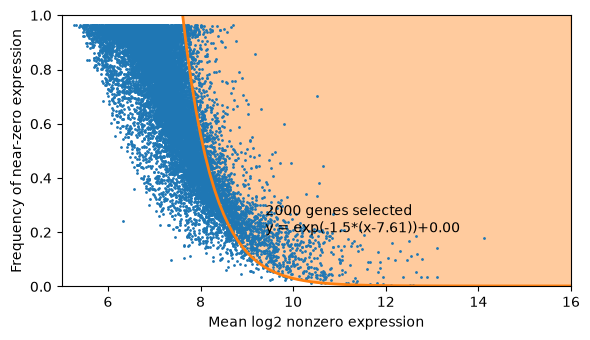

In [21]:
# Run gene selection function from berenslab/mini-atlas/code/ 
%matplotlib inline
from rnaseqTools import geneSelection

exc_selected_genes = geneSelection(
    data=exc_matrix.values,
    threshold=32,
    atleast=10,
    yoffset=0.002,
    decay=1.5,
    n=2000,
    plot=True,
)

In [22]:
# Extract the final 2,000 highly variable excitatory genes
exc_vargenes = exc_matrix.columns[exc_selected_genes]
exc_final_df = exc_matrix[exc_vargenes]
exc_final_df

,1700027H10Rik,2900097C17Rik,4930519F16Rik,4930555F03Rik,4932438A13Rik,5330434G04Rik,5430400D12Rik,5730455P16Rik,5730522E02Rik,6330403K07Rik,...,Zswim6,Zwint,Zxdb,mt-Co1,mt-Cytb,mt-Nd1,mt-Nd4l,mt-Nd5,mt-Rnr1,mt-Rnr2
20171204_sample_2,13,10190,4387,2,16,15,0,399,26,2476,...,47,7504,0,25779,47854,60796,48897,13268,36528,126532
20171204_sample_4,1,724,219,0,2910,840,0,7,25,35,...,3963,184,0,15623,37127,50946,30002,7966,24137,95167
20171204_sample_5,244,20602,1836,5,5852,1239,0,4740,2051,8401,...,4436,39958,1179,11646,32923,32862,15623,7133,8429,31441
20171204_sample_6,0,771,39,493,4890,1492,0,219,746,1043,...,2734,7093,0,4544,4431,4752,1945,1158,3828,11931
20171207_sample_2,0,491,839,15,2939,619,591,827,1653,706,...,5711,3615,6,4563,6470,6841,7955,2674,16847,42582
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20191114_sample_7,0,0,1350,1,2832,1635,0,1,3275,0,...,1032,2459,0,15084,14766,16873,9461,9537,12477,51123
20191114_sample_9,0,5531,0,0,6,1,0,0,0,793,...,0,14232,0,41918,35300,27630,14337,18409,7735,59472
20200106_sample_4,0,0,751,0,779,3,0,0,812,143,...,3404,1219,0,959,1159,683,776,839,1836,6177
20200225_sample_2,2,127,142,1,575,3,0,1,1191,0,...,958,757,0,581,535,421,304,332,264,1849


Chosen offset: 7.68


,1700001L05Rik,1810030O07Rik,2610008E11Rik,2610301B20Rik,2610316D01Rik,2810021J22Rik,2810407A14Rik,4632427E13Rik,4732496C06Rik,4930402H24Rik,...,Zranb2,Zscan12,Zswim6,Zwint,mt-Co1,mt-Cytb,mt-Nd1,mt-Nd4l,mt-Nd5,mt-Rnr2
20180213_sample_5,4,0,42,0,44,0,0,11,0,119,...,110,0,365,1860,1189,1661,1394,1218,600,1839
20180215_sample_1,0,56,0,547,780,0,0,0,0,348,...,2145,0,1250,11751,1171,10322,2373,1950,1065,1551
20180306_sample_1,0,244,0,0,0,0,0,67,0,227,...,100,0,954,257,1018,3115,1455,594,158,1773
20180327_sample_1,0,400,1,31,411,0,15,688,0,805,...,813,0,3333,2543,1093,1157,1837,1428,413,2868
20180327_sample_4,0,0,0,252,691,2,0,172,0,163,...,722,0,213,492,6423,12639,12829,6729,7402,22270
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20191107_sample_3,0,1249,109,1622,942,2,0,0,0,28,...,26,5,2,6376,20704,18057,12286,5936,8435,59409
20191107_sample_4,0,0,0,328,0,0,1,669,0,0,...,2728,1,93,2759,1719,2689,2878,1672,1494,10956
20191114_sample_1,1134,1,3038,0,296,0,1,771,648,998,...,0,0,1185,3536,4474,559,652,4116,994,10746
20191114_sample_4,0,0,8,0,1,0,0,89,0,611,...,4253,0,1135,3735,3335,3281,3524,465,237,8912


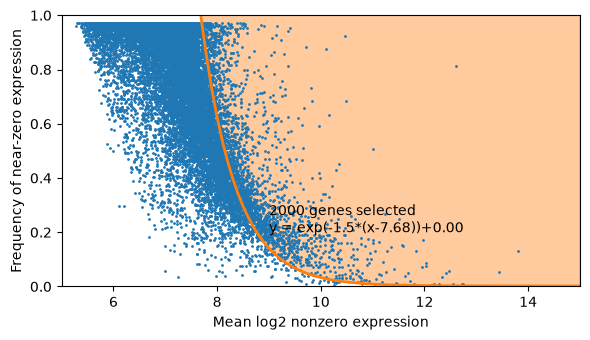

In [23]:
# Repeat the above for the inhibitory cells
inh_selected_genes = geneSelection(
    data=inh_matrix.values,
    threshold=32,
    atleast=10,
    yoffset=0.002,
    decay=1.5,
    n=2000,
    plot=True,
)

inh_vargenes = inh_matrix.columns[inh_selected_genes]
inh_final_df = inh_matrix[inh_vargenes]
inh_final_df

In [24]:
# Normalise and log transform the gene counts

# CPM Normalisation 
# Divide each cell (row) by its total count across the 2,000 genes, then multiply by 1M
exc_sums = exc_final_df.sum(axis=1)
exc_cpm = exc_final_df.div(exc_sums, axis=0) * 1e6
inh_sums = inh_final_df.sum(axis=1)
inh_cpm = inh_final_df.div(inh_sums, axis=0) * 1e6

# Log2(x + 1) Transformation
exc_log = np.log2(exc_cpm + 1)
inh_log = np.log2(inh_cpm + 1)

# Z-score scaling (transform for mean 0 and st.dev 1)
scaler = StandardScaler()
exc_scaled_data = scaler.fit_transform(exc_log)
exc_scaled_df = pd.DataFrame(
    exc_scaled_data, index=exc_log.index, columns=exc_log.columns
)
inh_scaled_data = scaler.fit_transform(inh_log)
inh_scaled_df = pd.DataFrame(
    inh_scaled_data, index=inh_log.index, columns=inh_log.columns
)

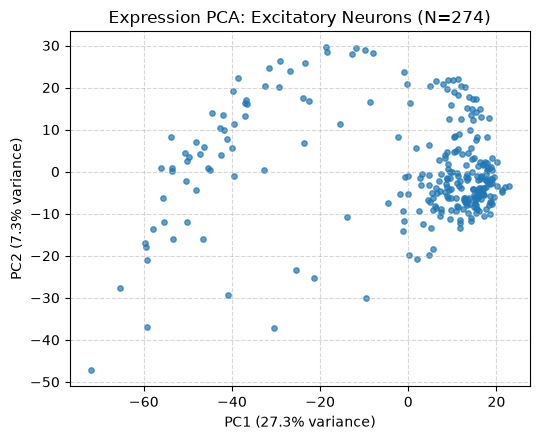

Total variance explained by top 10 PCs: 45.2%


In [25]:
# PCA for excitatory neurons
RANDOM_STATE = 42

pca_exc = PCA(n_components=10, random_state=RANDOM_STATE)
exc_pc_coords = pca_exc.fit_transform(exc_scaled_df)

exc_pc_cols = [f"Expression_PC{i+1}" for i in range(10)]
exc_expression_pcs = pd.DataFrame(
    exc_pc_coords, index=exc_scaled_df.index, columns=exc_pc_cols
)

## Plot
plt.figure(figsize=(5.5, 4.5))
plt.scatter(
    exc_expression_pcs["Expression_PC1"],
    exc_expression_pcs["Expression_PC2"],
    s=15,
    alpha=0.7,
    c="#1f77b4",
)
exc_var = pca_exc.explained_variance_ratio_ * 100
plt.title(f"Expression PCA: Excitatory Neurons (N={len(exc_scaled_df)})")
plt.xlabel(f"PC1 ({exc_var[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({exc_var[1]:.1f}% variance)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Total variance explained by top 10 PCs: {np.sum(exc_var):.1f}%")

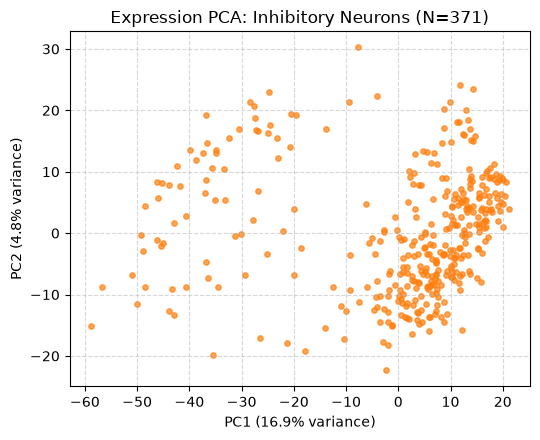

Total variance explained by top 10 PCs: 34.6%


In [26]:
# PCA for inhibitory neurons

pca_inh = PCA(n_components=10, random_state=RANDOM_STATE)
inh_pc_coords = pca_inh.fit_transform(inh_scaled_df)

inh_pc_cols = [f"Expression_PC{i+1}" for i in range(10)]
inh_expression_pcs = pd.DataFrame(
    inh_pc_coords, index=inh_scaled_df.index, columns=inh_pc_cols
)

## Plot
plt.figure(figsize=(5.5, 4.5))
plt.scatter(
    inh_expression_pcs["Expression_PC1"],
    inh_expression_pcs["Expression_PC2"],
    s=15,
    alpha=0.7,
    c="#ff7f0e",
)
inh_var = pca_inh.explained_variance_ratio_ * 100
plt.title(f"Expression PCA: Inhibitory Neurons (N={len(inh_scaled_df)})")
plt.xlabel(f"PC1 ({inh_var[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({inh_var[1]:.1f}% variance)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Total variance explained by top 10 PCs: {np.sum(inh_var):.1f}%")

In [27]:
# PCA preparation for morphologies

# Identify cells and features from morph_features DataFrame
exc_cell_ids = morph_features[morph_features["cell class"] == "exc"].index
exc_features_list = list(exc_features)
exc_morph_raw = morph_features.loc[exc_cell_ids, exc_features_list]

inh_cell_ids = morph_features[morph_features["cell class"] == "inh"].index
inh_features_list = list(inh_features)
inh_morph_raw = morph_features.loc[inh_cell_ids, inh_features_list]

# Handle missing values (Impute with column median)
imputer = SimpleImputer(strategy="median")
exc_morph_imputed = imputer.fit_transform(exc_morph_raw)
inh_morph_imputed = imputer.fit_transform(inh_morph_raw)

# Z-score scale the features
scaler = StandardScaler()
exc_morph_scaled = scaler.fit_transform(exc_morph_imputed)
exc_morph_scaled_df = pd.DataFrame(
    exc_morph_scaled, index=exc_morph_raw.index, columns=exc_morph_raw.columns
)
inh_morph_scaled = scaler.fit_transform(inh_morph_imputed)
inh_morph_scaled_df = pd.DataFrame(
    inh_morph_scaled, index=inh_morph_raw.index, columns=inh_morph_raw.columns
)

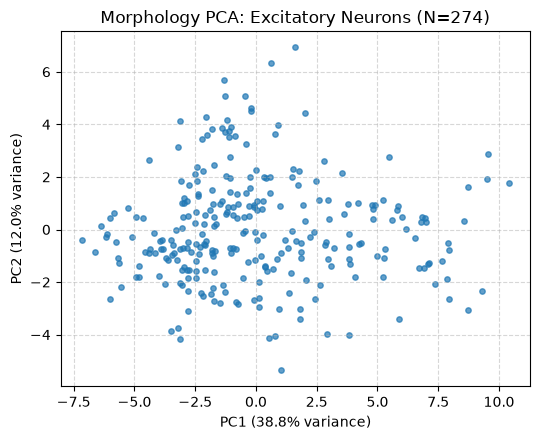

Total variance explained by top 10 Excitatory Morphology PCs: 87.8%


In [28]:
# PCA for excitatory neurons

pca_morph_exc = PCA(n_components=10, random_state=RANDOM_STATE)
exc_morph_pc_coords = pca_morph_exc.fit_transform(exc_morph_scaled_df)

# Store in a clean DataFrame
exc_morph_pc_cols = [f"Morphology_PC{i+1}" for i in range(10)]
exc_morphology_pcs = pd.DataFrame(
    exc_morph_pc_coords, index=exc_morph_raw.index, columns=exc_morph_pc_cols
)

# --- 5. Plotting ---
plt.figure(figsize=(5.5, 4.5))
plt.scatter(
    exc_morphology_pcs["Morphology_PC1"],
    exc_morphology_pcs["Morphology_PC2"],
    s=15,
    alpha=0.7,
    c="#1f77b4",
)
exc_m_var = pca_morph_exc.explained_variance_ratio_ * 100

plt.title(
    f"Morphology PCA: Excitatory Neurons (N={len(exc_morphology_pcs)})"
)
plt.xlabel(f"PC1 ({exc_m_var[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({exc_m_var[1]:.1f}% variance)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Total variance explained by top 10 Excitatory Morphology PCs: {np.sum(exc_m_var):.1f}%")

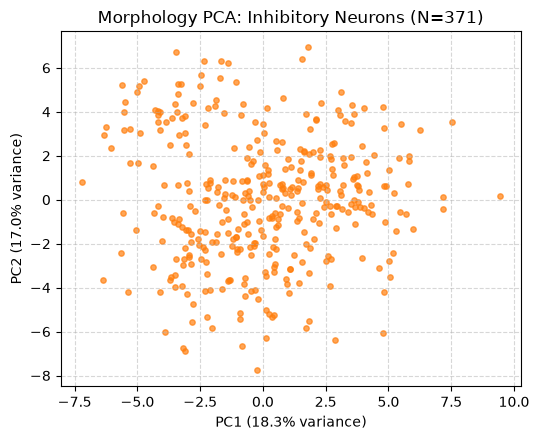

Total variance explained by top 10 Inhibitory Morphology PCs: 72.6%


In [29]:
# PCA for inhibitory neurons

pca_morph_inh = PCA(n_components=10, random_state=RANDOM_STATE)
inh_morph_pc_coords = pca_morph_inh.fit_transform(inh_morph_scaled_df)

inh_morph_pc_cols = [f"Morphology_PC{i+1}" for i in range(10)]
inh_morphology_pcs = pd.DataFrame(
    inh_morph_pc_coords, index=inh_morph_raw.index, columns=inh_morph_pc_cols
)

# Plot
plt.figure(figsize=(5.5, 4.5))
plt.scatter(
    inh_morphology_pcs["Morphology_PC1"],
    inh_morphology_pcs["Morphology_PC2"],
    s=15,
    alpha=0.7,
    c="#ff7f0e",
)
inh_m_var = pca_morph_inh.explained_variance_ratio_ * 100

plt.title(
    f"Morphology PCA: Inhibitory Neurons (N={len(inh_morphology_pcs)})"
)
plt.xlabel(f"PC1 ({inh_m_var[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({inh_m_var[1]:.1f}% variance)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Total variance explained by top 10 Inhibitory Morphology PCs: {np.sum(inh_m_var):.1f}%")

### <div style = 'background-color:PapayaWhip'> **Pairwise PC Correlation**</div>

#### **Excitatory Neurons**

In [30]:
# Since cells are identical, sort both dataframes by their index to align row orders
exc_expression_pcs = exc_expression_pcs.sort_index()
exc_morphology_pcs = exc_morphology_pcs.sort_index()

X_exc_expr = exc_expression_pcs.values  # N x 10
Y_exc_morph = exc_morphology_pcs.values  # N x 10
n_cells_exc = X_exc_expr.shape[0]

# Compute  Pearson r and p-values
true_r_matrix_exc = np.zeros((10, 10))
analytical_p_matrix_exc = np.zeros((10, 10))

for i in range(10):
    for j in range(10):
        r, p = pearsonr(X_exc_expr[:, i], Y_exc_morph[:, j])
        true_r_matrix_exc[i, j] = r
        analytical_p_matrix_exc[i, j] = p

In [31]:
# Permutation Testing (1,000 iterations)
n_permutations = 1000
greater_than_null_counts_exc = np.zeros((10, 10))

np.random.seed(42)

for p_iter in range(n_permutations):
    # Shuffle the morphology row indices to break the biological link
    shuffled_indices = np.random.permutation(n_cells_exc)
    Y_morph_shuffled = Y_exc_morph[shuffled_indices, :]

    for i in range(10):
        for j in range(10):
            r_null, _ = pearsonr(X_exc_expr[:, i], Y_morph_shuffled[:, j])
            # Two-tailed absolute magnitude comparison
            if np.abs(r_null) >= np.abs(true_r_matrix_exc[i, j]):
                greater_than_null_counts_exc[i, j] += 1

empirical_p_matrix_exc = greater_than_null_counts_exc / n_permutations

# Multiple Testing Correction (False-Discovery Rate) ---
flat_r_exc = true_r_matrix_exc.flatten()
flat_p_empirical_exc = empirical_p_matrix_exc.flatten()

# Apply Benjamini-Hochberg FDR correction on permutation p-values
_, fdr_p_empirical_exc, _, _ = multipletests(
    flat_p_empirical_exc, alpha=0.05, method="fdr_bh")
fdr_p_empirical_exc = fdr_p_empirical_exc.reshape(10, 10)

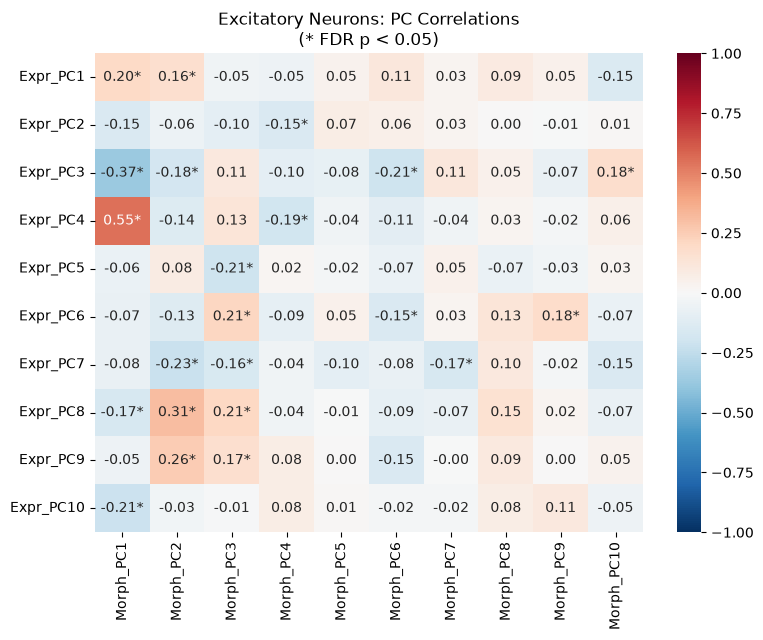

In [32]:
# Plot
plt.figure(figsize=(8, 6.5))
significance_mask = fdr_p_empirical_exc < 0.05

annot_labels = np.empty((10, 10), dtype=object)
for i in range(10):
    for j in range(10):
        star = "*" if significance_mask[i, j] else ""
        annot_labels[i, j] = f"{true_r_matrix_exc[i, j]:.2f}{star}"

sns.heatmap(
    true_r_matrix_exc,
    annot=annot_labels,
    fmt="",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    xticklabels=[f"Morph_PC{i+1}" for i in range(10)],
    yticklabels=[f"Expr_PC{i+1}" for i in range(10)],
)
plt.title("Excitatory Neurons: PC Correlations\n(* FDR p < 0.05)")
plt.tight_layout()
plt.show()

In [43]:
# Pull gene loadings for Expr_PC4
expr_pc4_loadings = pd.Series(pca_exc.components_[3], index=exc_scaled_df.columns)

print("Top genes driving PC4")
print("Positive drivers (associated with high Morph_PC1):")
print(expr_pc4_loadings.sort_values(ascending=False).head(10))
print("\nNegative drivers:")
print(expr_pc4_loadings.sort_values(ascending=True).head(10))

Top genes driving PC4
Positive drivers (associated with high Morph_PC1):
Fezf2      0.107321
Coro6      0.094253
Tox        0.090083
Tox2       0.081522
Gm49948    0.080009
Parm1      0.079595
Flt3       0.078279
Lgr5       0.076358
Gm23153    0.074453
Nkain3     0.074379
dtype: float64

Negative drivers:
Unc5d     -0.083683
Calb1     -0.079322
Cux2      -0.075190
Rasgrf2   -0.074743
Pparg     -0.072028
Prkg1     -0.069355
Kcnc2     -0.066263
Slc4a4    -0.063548
Slc30a3   -0.061970
Mapk4     -0.060487
dtype: float64


In [34]:
# Pull morphological loadings for Morph_PC1
# Index 0 corresponds to PC1
morph_pc1_loadings = pd.Series(pca_morph_exc.components_[0], index=exc_morph_scaled_df.columns)

print("Top morph features driving PC1:")
print("Positive structural features:")
print(morph_pc1_loadings.sort_values(ascending=False).head(5))
print("\nNegative structural features:")
print(morph_pc1_loadings.sort_values(ascending=True).head(5))


Top morph features driving PC1:
Positive structural features:
"apical" total length                 0.248434
dendrite max path distance to soma    0.246348
dendrite max Euclidean dist           0.242465
"apical" robust height                0.241888
"apical" height                       0.240342
dtype: float64

Negative structural features:
dendrite min branch angle      -0.127041
dendrite log min tortuosity    -0.109382
dendrite mean neurite radius   -0.079301
stems exiting down             -0.057227
stems exiting up                0.018533
dtype: float64


#### **Inhibitory Neurons**

In [35]:
# Sort rows
inh_expression_pcs = inh_expression_pcs.sort_index()
inh_morphology_pcs = inh_morphology_pcs.sort_index()

X_inh_expr = inh_expression_pcs.values
Y_inh_morph = inh_morphology_pcs.values
n_cells_inh = X_inh_expr.shape[0]

# Compute Pearson r
true_r_matrix_inh = np.zeros((10, 10))
analytical_p_matrix_inh = np.zeros((10, 10))

for i in range(10):
    for j in range(10):
        r, p = pearsonr(X_inh_expr[:, i], Y_inh_morph[:, j])
        true_r_matrix_inh[i, j] = r
        analytical_p_matrix_inh[i, j] = p

In [36]:
# Permutation Testing (x1000)
greater_than_null_counts_inh = np.zeros((10, 10))

for p_iter in range(n_permutations):
    shuffled_indices = np.random.permutation(n_cells_inh)
    Y_morph_shuffled = Y_inh_morph[shuffled_indices, :]

    for i in range(10):
        for j in range(10):
            r_null, _ = pearsonr(X_inh_expr[:, i], Y_morph_shuffled[:, j])
            if np.abs(r_null) >= np.abs(true_r_matrix_inh[i, j]):
                greater_than_null_counts_inh[i, j] += 1

empirical_p_matrix_inh = greater_than_null_counts_inh / n_permutations

# Multiple Testing Correction (FDR)
flat_r_inh = true_r_matrix_inh.flatten()
flat_p_empirical_inh = empirical_p_matrix_inh.flatten()

_, fdr_p_empirical_inh, _, _ = multipletests(
    flat_p_empirical_inh, alpha=0.05, method="fdr_bh")
fdr_p_empirical_inh = fdr_p_empirical_inh.reshape(10, 10)

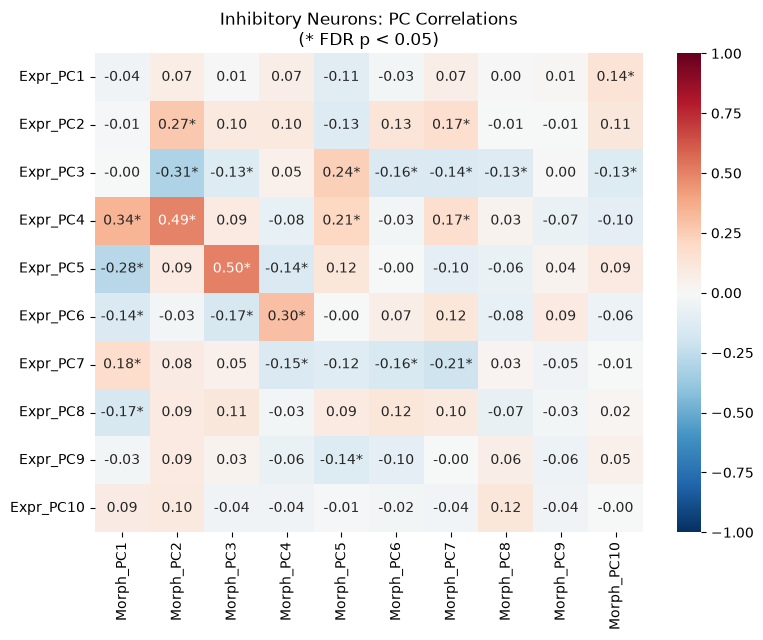

In [37]:
# Plot
plt.figure(figsize=(8, 6.5))
significance_mask_inh = fdr_p_empirical_inh < 0.05

annot_labels_inh = np.empty((10, 10), dtype=object)
for i in range(10):
    for j in range(10):
        star = "*" if significance_mask_inh[i, j] else ""
        annot_labels_inh[i, j] = f"{true_r_matrix_inh[i, j]:.2f}{star}"

sns.heatmap(
    true_r_matrix_inh,
    annot=annot_labels_inh,
    fmt="",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    xticklabels=[f"Morph_PC{i+1}" for i in range(10)],
    yticklabels=[f"Expr_PC{i+1}" for i in range(10)],
)
plt.title("Inhibitory Neurons: PC Correlations\n(* FDR p < 0.05)")
plt.tight_layout()
plt.show()

In [38]:
# Example 1: Expr_PC5 vs Morph_PC3 (r = 0.50)

# Extract gene loadings for PC5
expr_pc5_loadings = pd.Series(pca_inh.components_[4], index=inh_scaled_df.columns)

print("Top Genes Driving Inhibitory Features PC5")
print("Positive drivers (associated with high Morph_PC3):")
print(expr_pc5_loadings.sort_values(ascending=False).head(10))
print("\nNegative drivers:")
print(expr_pc5_loadings.sort_values(ascending=True).head(10))

Top Genes Driving Inhibitory Features PC5
Positive drivers (associated with high Morph_PC3):
Lamp5       0.112405
Cplx3       0.086975
Ndnf        0.077100
Bmp3        0.075815
Mpped1      0.074024
Atp6ap1l    0.073002
Cd14        0.072887
H2-Q6       0.072179
Irf5        0.069292
Ptprm       0.067774
dtype: float64

Negative drivers:
Penk      -0.072235
Vip       -0.069662
Sema5b    -0.069076
Glra2     -0.067475
Galnt18   -0.066245
Cbln2     -0.065493
Lama3     -0.062187
Fbln2     -0.060517
Synpr     -0.060083
Ano4      -0.058804
dtype: float64


In [39]:
# Extract morph loadings for PC3
morph_pc3_loadings = pd.Series(pca_morph_inh.components_[2], index=inh_morph_scaled_df.columns)

print("Top Morph Features Driving PC3")
print("Positive structural features:")
print(morph_pc3_loadings.sort_values(ascending=False).head(5))
print("\nNegative structural features:")
print(morph_pc3_loadings.sort_values(ascending=True).head(5))

Top Morph Features Driving PC3
Positive structural features:
dendrite tips             0.282457
dendrite branch points    0.253791
stems                     0.249583
axon branch points        0.234198
axon tips                 0.231579
dtype: float64

Negative structural features:
axon log min tortuosity               -0.249240
axon robust height                    -0.216613
axon bifurcation standard deviation   -0.209420
stems exiting up                      -0.170727
axon height                           -0.167381
dtype: float64


In [40]:
# Example 2: Expr_PC4 vs Morph_PC2 (True r = 0.45)

# Extract Gene Loadings for Expr_PC4 (Index 3)
expr_pc4_inh_loadings = pd.Series(pca_inh.components_[3], index=inh_scaled_df.columns)

print("Top Genes Driving Inhibitory Features PC4")
print("Positive drivers (associated with high Morph_PC2):")
print(expr_pc4_inh_loadings.sort_values(ascending=False).head(10))
print("\nNegative drivers:")
print(expr_pc4_inh_loadings.sort_values(ascending=True).head(10))

Top Genes Driving Inhibitory Features PC4
Positive drivers (associated with high Morph_PC2):
Sst       0.116226
Crhbp     0.094701
Lama4     0.093394
Pdyn      0.092496
Unc13c    0.091902
Grin3a    0.087359
Pde1a     0.081147
Prkcg     0.078638
Tox       0.078237
Stxbp6    0.077833
dtype: float64

Negative drivers:
Erbb4    -0.093224
Nfib     -0.085878
Dab1     -0.085608
Sez6     -0.084352
Adarb2   -0.077530
Shisa9   -0.077529
Zmat4    -0.077047
Gabrg3   -0.075392
Csmd3    -0.074927
Lrrc4c   -0.074378
dtype: float64


In [41]:
# Extract Morphological Feature Loadings for Morph_PC2 (Index 1)
morph_pc2_loadings = pd.Series(pca_morph_inh.components_[1], index=inh_morph_scaled_df.columns)

print("Top morph features driving PC2")
print("Positive structural features:")
print(morph_pc2_loadings.sort_values(ascending=False).head(5))
print("\nNegative structural features:")
print(morph_pc2_loadings.sort_values(ascending=True).head(5))

Top morph features driving PC2
Positive structural features:
axon total length                        0.257496
Log1p fraction of axon above dendrite    0.235993
axon width                               0.215447
axon max path distance to soma           0.215360
axon first bifurcation moment            0.209203
dtype: float64

Negative structural features:
dendrite max branch order                 -0.192311
Log1p fraction of dendrite above axon     -0.180267
axon min branch angle                     -0.168685
dendrite branch points                    -0.167747
dendrite bifurcation standard deviation   -0.162277
dtype: float64


### <div style = 'background-color:PapayaWhip'> **Functional Relationship**</div>

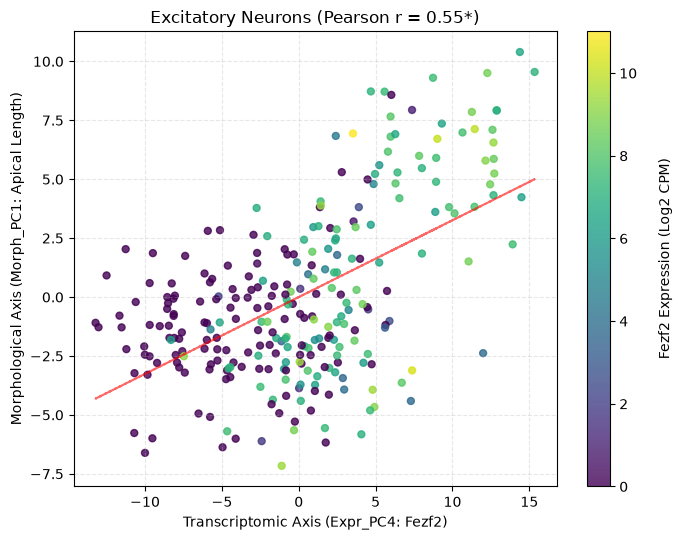

In [52]:
plt.figure(figsize=(7, 5.5))

# Color cells by Fezf2 expression
fezf2_expression = exc_log["Fezf2"]

scatter = plt.scatter(
    exc_expression_pcs["Expression_PC4"],
    exc_morphology_pcs["Morphology_PC1"],
    c=fezf2_expression,
    cmap="viridis",
    s=25,
    alpha=0.8,
)

# Add trendline
m, b = np.polyfit(
    exc_expression_pcs["Expression_PC4"],
    exc_morphology_pcs["Morphology_PC1"],
    1,
)
plt.plot(
    exc_expression_pcs["Expression_PC4"],
    m * exc_expression_pcs["Expression_PC4"] + b,
    color="red",
    linestyle="--",
    alpha=0.6,
)

cbar = plt.colorbar(scatter)
cbar.set_label("Fezf2 Expression (Log2 CPM)", labelpad=15)

plt.title("Excitatory Neurons (Pearson r = 0.55*)")
plt.xlabel("Transcriptomic Axis (Expr_PC4: Fezf2)")
plt.ylabel("Morphological Axis (Morph_PC1: Apical Length)")
plt.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()